## Этап 3, часть 1. Анализ матчей CS2 на FACEIT

Кукин Олег АД-24

[Датасет на Kaggle](https://www.kaggle.com/datasets/piercehentosh/counter-strike-2-win-prediction-faceit)

## 1 Загрузка данных

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("win_prediction_data_clean1.csv", sep=";")

## 2 Проверка и очистка данных

In [ ]:
df.isna().sum()

win                          0
map                          0
Team_A_avg_win_percentage    0
Team_A_avg_KR                0
Team_A_avg_elo               0
Team_B_avg_win_percentage    0
Team_B_avg_KR                0
Team_B_avg_elo               0
Match ID                     0
dtype: int64

In [ ]:
print("Полных дубликатов:", df.duplicated().sum())
print("Повторных записей по ID сверх первой:", df["Match ID"].duplicated().sum())

Полных дубликатов: 0
Повторных записей по ID сверх первой: 534


In [ ]:
print("Процент побед A вне 0-100:", ((df["Team_A_avg_win_percentage"] < 0) | (df["Team_A_avg_win_percentage"] > 100)).sum())
print("Процент побед B вне 0-100:", ((df["Team_B_avg_win_percentage"] < 0) | (df["Team_B_avg_win_percentage"] > 100)).sum())
print("K/R A ниже нуля:", (df["Team_A_avg_KR"] < 0).sum())
print("K/R B ниже нуля:", (df["Team_B_avg_KR"] < 0).sum())
print("ELO A не больше нуля:", (df["Team_A_avg_elo"] <= 0).sum())
print("ELO B не больше нуля:", (df["Team_B_avg_elo"] <= 0).sum())

Процент побед A вне 0-100: 0
Процент побед B вне 0-100: 0
K/R A ниже нуля: 0
K/R B ниже нуля: 0
ELO A не больше нуля: 0
ELO B не больше нуля: 0


In [ ]:
df["win"].unique()

array(['team a', 'team b'], dtype=object)

In [ ]:
map_counts = df.groupby("Match ID")["map"].nunique()
win_counts = df.groupby("Match ID")["win"].nunique()
print("ID с разными картами:", (map_counts > 1).sum())
print("ID с разными победителями:", (win_counts > 1).sum())

ID с разными картами: 0
ID с разными победителями: 0


In [ ]:
df = df.drop_duplicates(subset="Match ID", keep="first").copy()
print("Матчей после очистки:", len(df))
print("Повторов ID после очистки:", df["Match ID"].duplicated().sum())

Матчей после очистки: 9117
Повторов ID после очистки: 0


## 3 Разница показателей команд A и B

In [ ]:
df["elo_diff"] = df["Team_A_avg_elo"] - df["Team_B_avg_elo"]
df["kr_diff"] = df["Team_A_avg_KR"] - df["Team_B_avg_KR"]
df["winrate_diff"] = df["Team_A_avg_win_percentage"] - df["Team_B_avg_win_percentage"]

## 4 Разделение данных: 30% и 70%

In [ ]:
eda = df.sample(frac=0.30, random_state=42)
check = df.drop(eda.index)
print("Для исследования:", len(eda))
print("Для проверки:", len(check))

Для исследования: 2735
Для проверки: 6382


## 5 Среднее и медиана на 30% данных

In [ ]:
features = ["elo_diff", "kr_diff", "winrate_diff"]

## Среднее

In [ ]:
eda[features].mean().round(4)

elo_diff        114.3499
kr_diff           0.0016
winrate_diff      0.0347
dtype: float64

## Медиана

In [ ]:
eda[features].median().round(4)

elo_diff        130.8000
kr_diff           0.0011
winrate_diff      0.0080
dtype: float64

## 6 Графики и гипотезы

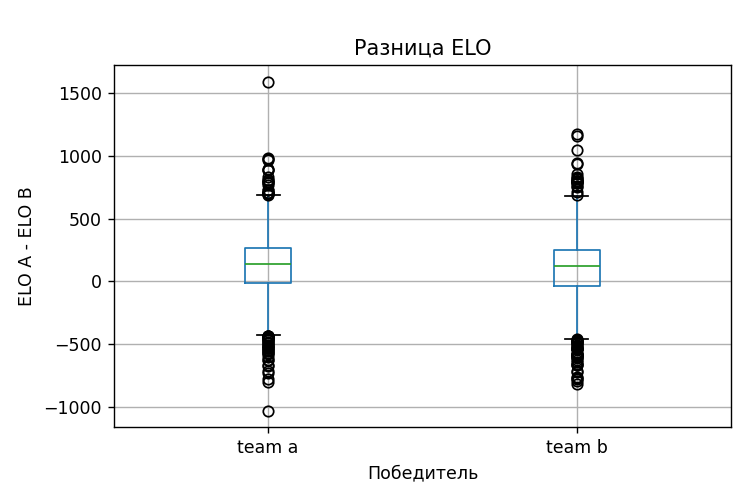

In [ ]:
eda.boxplot(column="elo_diff", by="win", figsize=(6, 4))
plt.title("Разница ELO")
plt.suptitle("")
plt.xlabel("Победитель")
plt.ylabel("ELO A - ELO B")
plt.tight_layout()
plt.show()

### При победах A медиана разницы ELO немного выше. Гипотеза 1: доля побед A выше при преимуществе по ELO, чем при отставании.

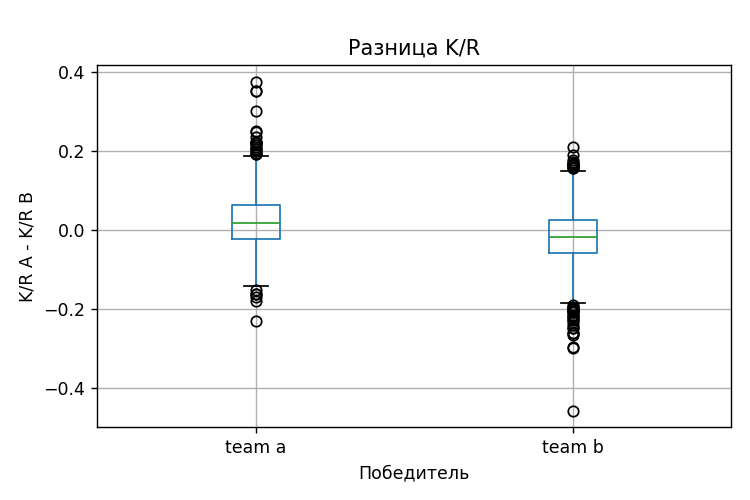

In [ ]:
eda.boxplot(column="kr_diff", by="win", figsize=(6, 4))
plt.title("Разница K/R")
plt.suptitle("")
plt.xlabel("Победитель")
plt.ylabel("K/R A - K/R B")
plt.tight_layout()
plt.show()

### При победах A медиана разницы K/R положительная. Гипотеза 2: доля побед A выше при преимуществе по K/R, чем при отставании.

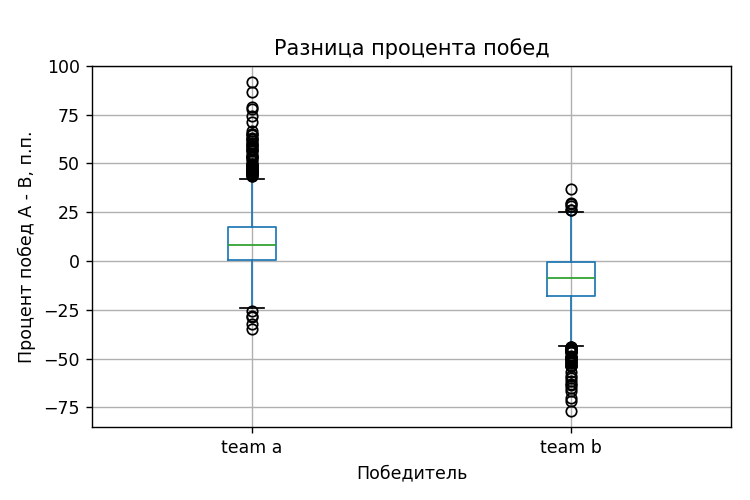

In [ ]:
eda.boxplot(column="winrate_diff", by="win", figsize=(6, 4))
plt.title("Разница процента побед")
plt.suptitle("")
plt.xlabel("Победитель")
plt.ylabel("Процент побед A - B, п.п.")
plt.tight_layout()
plt.show()

### При победах A медиана разницы процента побед положительная. Гипотеза 3: доля побед A выше при преимуществе по проценту побед, чем при отставании.

## 7 Проверка гипотез на остальных 70%

## 7.1 ELO

In [ ]:
higher = check[check["elo_diff"] > 0]
lower = check[check["elo_diff"] < 0]

In [ ]:
wins_higher = (higher["win"] == "team a").sum()
wins_lower = (lower["win"] == "team a").sum()
percent_higher = wins_higher / len(higher) * 100
percent_lower = wins_lower / len(lower) * 100

In [ ]:
print("A выше:", len(higher), "матчей,", wins_higher, "побед A,", round(percent_higher, 2), "%")
print("A ниже:", len(lower), "матчей,", wins_lower, "побед A,", round(percent_lower, 2), "%")
print("Разница:", round(percent_higher - percent_lower, 2), "п.п.")
print("Равные показатели:", (check["elo_diff"] == 0).sum(), "матчей")

A выше: 4511 матчей, 2265 побед A, 50.21 %
A ниже: 1867 матчей, 910 побед A, 48.74 %
Разница: 1.47 п.п.
Равные показатели: 4 матчей


## 7.2 K/R

In [ ]:
higher = check[check["kr_diff"] > 0]
lower = check[check["kr_diff"] < 0]

In [ ]:
wins_higher = (higher["win"] == "team a").sum()
wins_lower = (lower["win"] == "team a").sum()
percent_higher = wins_higher / len(higher) * 100
percent_lower = wins_lower / len(lower) * 100

In [ ]:
print("A выше:", len(higher), "матчей,", wins_higher, "побед A,", round(percent_higher, 2), "%")
print("A ниже:", len(lower), "матчей,", wins_lower, "побед A,", round(percent_lower, 2), "%")
print("Разница:", round(percent_higher - percent_lower, 2), "п.п.")
print("Равные показатели:", (check["kr_diff"] == 0).sum(), "матчей")

A выше: 3153 матчей, 1989 побед A, 63.08 %
A ниже: 3229 матчей, 1187 побед A, 36.76 %
Разница: 26.32 п.п.
Равные показатели: 0 матчей


## 7.3 Процент побед

In [ ]:
higher = check[check["winrate_diff"] > 0]
lower = check[check["winrate_diff"] < 0]

In [ ]:
wins_higher = (higher["win"] == "team a").sum()
wins_lower = (lower["win"] == "team a").sum()
percent_higher = wins_higher / len(higher) * 100
percent_lower = wins_lower / len(lower) * 100

In [ ]:
print("A выше:", len(higher), "матчей,", wins_higher, "побед A,", round(percent_higher, 2), "%")
print("A ниже:", len(lower), "матчей,", wins_lower, "побед A,", round(percent_lower, 2), "%")
print("Разница:", round(percent_higher - percent_lower, 2), "п.п.")
print("Равные показатели:", (check["winrate_diff"] == 0).sum(), "матчей")

A выше: 3218 матчей, 2471 побед A, 76.79 %
A ниже: 3162 матчей, 703 побед A, 22.23 %
Разница: 54.55 п.п.
Равные показатели: 2 матчей


## 8 Вывод

### На проверочных данных разница долей побед A составила 1,47 п.п. для ELO, 26,32 п.п. для K/R и 54,55 п.п. для процента побед. Гипотезы 2 и 3 получили поддержку, различие по ELO небольшое. Это наблюдаемые связи, а не готовый прогноз: время сбора статистики неизвестно.